# Building 4 & 6 — Seven Requested Model Families
## Summary
Executed 120 model fits: ten configurations from seven regression families across six chronological months and two buildings. Three simple baselines are reference-only. No other notebook needs to be running.

| Building | Month | Selection | Model | Within ±10% | RMSE (kW) | R² |
|---|---|---|---|---:|---:|---:|
| Building4 | Oct | Validation match | SVR | 43.23% | 0.4872 | -0.080 |
| Building4 | Oct | Validation RMSE | Random Forest | 17.09% | 0.4571 | 0.049 |
| Building4 | Nov | Validation match | SVR | 23.24% | 0.4833 | 0.181 |
| Building4 | Nov | Validation RMSE | Random Forest | 4.11% | 0.4736 | 0.213 |
| Building6 | Oct | Validation match | Random Forest peers | 74.16% | 3.0257 | 0.739 |
| Building6 | Oct | Validation RMSE | Random Forest peers | 74.16% | 3.0257 | 0.739 |
| Building6 | Nov | Validation match | Random Forest peers | 83.09% | 4.1108 | 0.642 |
| Building6 | Nov | Validation RMSE | Random Forest peers | 83.09% | 4.1108 | 0.642 |

Model selection uses earlier validation months only. The separate retrospective maximum is descriptive, not a deployment selection rule. Match rate, RMSE and R² measure different aspects of performance. These are known-weather historical evaluations.

## Method
- October: train on all eligible observations before 1 October 2020. November: retrain through 31 October, including October **actual** observations, then forecast November. Predicted labels are not treated as actual training targets.
- Select October models using June–September backtests; select November models using June–October. Each fold fits preprocessing and models only on earlier data. These repeatedly inspected historical months are exploratory backtests, not untouched tests.
- Two selection objectives are reported: highest validation ±10% match rate and lowest validation RMSE. A separate retrospective maximum is explicitly labelled and is not a deployable selection rule.
- Month boundaries are UTC; calendar features use Melbourne time and the previously supplied FEATURES_CODE logic. Calendar restrictions and facility schedules are proxies, not measured occupancy.
- Observed ERA5 weather in the forecast month is a **known-weather scenario**. Operational forecasts would need weather forecasts. No current-month building or solar observations enter a monthly prediction.
- All previous history is retained. Missing input features use training-only imputation; missing targets remain missing. Hourly means can contain fewer than four observed quarters, consistent with the previous analysis.
- Predictions are hourly and repeated onto 15-minute timestamps. Main rankings use identical observed **15-minute** targets. Hourly scores are also exported, separately labelled.
- Match rate = percentage of nonzero actual readings with absolute relative error ≤10%. R² is not accuracy; RMSE is in kW. MASE uses a pre-origin 28-day seasonal difference. Constant baselines remain visible because a high match rate can hide poor peak prediction.

## 1. Setup
Required packages: numpy, pandas, matplotlib, scikit-learn, xgboost, joblib. Paths below point to your computer.

In [1]:
import os
for key in ['OMP_NUM_THREADS','OPENBLAS_NUM_THREADS','MKL_NUM_THREADS']: os.environ[key]='1'
from pathlib import Path
from datetime import datetime
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.exceptions import ConvergenceWarning
import warnings, json, joblib, contextlib,io

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.feature_selection import VarianceThreshold
from xgboost import XGBRegressor
import sklearn, xgboost, time
DATA=Path(r'C:\Users\50851\Desktop\ADS2002\MonashSolarFarm')
OUT=Path(r'C:\Users\50851\Documents\Codex\2026-08-14\kan\outputs\building46_requested_models')
OUT.mkdir(parents=True,exist_ok=True)
LOCAL_TZ='Australia/Melbourne'
plt.rcParams.update({'font.size':10,'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print('sklearn:',sklearn.__version__,'xgboost:',xgboost.__version__)


sklearn: 1.5.1 xgboost: 3.4.1


## 2. Load and validate the existing TSF data pipeline

In [2]:
def load_tsf(path):
    """
    Read a .tsf file.

    Returns a dict of {series_name: pandas Series}, each with a proper
    15-minute UTC DatetimeIndex reconstructed from its own start timestamp.
    """
    series = {}
    with open(path) as fh:
        for line in fh:
            line = line.rstrip("\n")

            # Skip comments, blank lines, and the @tag header lines.
            if not line or line.startswith("#") or line.startswith("@"):
                continue

            # Everything after @data has the shape  name:timestamp:v1,v2,v3,...
            name, timestamp, values = line.split(":", 2)

            # "2016-07-03 21-30-00"  ->  a real timestamp, tagged as UTC
            start = pd.Timestamp(datetime.strptime(timestamp, "%Y-%m-%d %H-%M-%S"), tz="UTC")

            # "?" marks a missing reading
            numbers = [np.nan if v == "?" else float(v) for v in values.split(",")]

            # Build the dates by stepping forward 15 minutes at a time
            index = pd.date_range(start=start, periods=len(numbers), freq="15min", tz="UTC")

            series[name] = pd.Series(numbers, index=index, name=name)
    return series




raw=pd.DataFrame(load_tsf(DATA/'nov_data.tsf')).asfreq('15min')
phase2=pd.DataFrame(load_tsf(DATA/'phase_2_data.tsf')).asfreq('15min')
for b in ['Building4','Building5','Building6']:
    pd.testing.assert_series_equal(phase2[b],raw[b].reindex(phase2.index),check_freq=False)
raw=raw.loc[raw.index<pd.Timestamp('2020-12-01',tz='UTC')]
assert raw.index.is_unique and raw.index.is_monotonic_increasing
hourly=raw.resample('h').mean()
wx=pd.read_csv(DATA/'ERA5_Weather_Data_Monash.csv')
wx.index=pd.to_datetime(wx.pop('datetime (UTC)'),utc=True)
wx=wx.select_dtypes('number').drop(columns=['utc_offset (hrs)'],errors='ignore').resample('h').mean()
folds={pd.Timestamp(f'2020-{m:02d}-01',tz='UTC').strftime('%b'):
       (pd.Timestamp(f'2020-{m:02d}-01',tz='UTC'),pd.Timestamp(f'2020-{m+1:02d}-01',tz='UTC'))
       for m in range(6,12)}
coverage=[]
for b in ['Building4','Building6']:
    for month,(lo,hi) in folds.items():
        z=raw[b].reindex(pd.date_range(lo,hi,freq='15min',inclusive='left'))
        coverage.append(dict(Building=b,Month=month,Expected=len(z),Observed=z.count(),Observed_pct=100*z.notna().mean()))
coverage=pd.DataFrame(coverage)
coverage.to_csv(OUT/'coverage.csv',index=False)
display(coverage[coverage.Month.isin(['Oct','Nov'])].round(2))


,Building,Month,Expected,Observed,Observed_pct
4,Building4,Oct,2976,1691,56.82
5,Building4,Nov,2880,1850,64.24
10,Building6,Oct,2976,2972,99.87
11,Building6,Nov,2880,2874,99.79


## 3. Supplied calendar features, ERA5 weather, and pre-origin history
History features lag 35 days, which exceeds either forecast month. Mean/median imputation is fitted separately in every fold.

In [3]:
calendar_code='import pandas as pd\nimport numpy as np\n\n# ============================================================\n# 0. PREPARE DATETIME INDEX\n# ============================================================\n\nFeature_dataset.index = pd.to_datetime(Feature_dataset.index)\nFeature_dataset = Feature_dataset.sort_index()\n\ndate = Feature_dataset.index.normalize()\nhour = Feature_dataset.index.hour\nminute = Feature_dataset.index.minute\ntime_minutes = hour * 60 + minute\n\n\n# ============================================================\n# 1. HELPER FUNCTION FOR DATE RANGES\n# ============================================================\n\ndef in_date_ranges(index, ranges):\n    dates = index.normalize()\n    mask = pd.Series(False, index=index)\n\n    for start, end in ranges:\n        start = pd.Timestamp(start)\n        end = pd.Timestamp(end)\n\n        mask |= (dates >= start) & (dates <= end)\n\n    return mask.astype(int).values\n\n\n# ============================================================\n# 2. WEEKDAY / WEEKEND\n# ============================================================\n\nFeature_dataset["is_weekday"] = (\n    Feature_dataset.index.dayofweek < 5\n).astype(int)\n\nFeature_dataset["is_weekend"] = (\n    Feature_dataset.index.dayofweek >= 5\n).astype(int)\n\n\n# ============================================================\n# 3. UNIVERSITY OPEN / CLOSED\n# ============================================================\n\nuniversity_open_ranges = [\n    ("2016-01-04", "2016-12-22"),\n    ("2017-01-03", "2017-12-21"),\n    ("2018-01-02", "2018-12-21"),\n    ("2019-01-02", "2019-12-23"),\n    ("2020-01-02", "2020-12-23"),\n]\n\nFeature_dataset["university_open"] = in_date_ranges(\n    Feature_dataset.index,\n    university_open_ranges\n)\n\nFeature_dataset["university_closed"] = (\n    1 - Feature_dataset["university_open"]\n)\n\n\n# ============================================================\n# 4. CAMPUS FACILITY HOURS\n# Mon-Fri: 09:00 - 17:00\n# ============================================================\n\ncampus_time_open = (\n    (time_minutes >= 9 * 60) &\n    (time_minutes < 17 * 60)\n)\n\nFeature_dataset["campus_facility_hours"] = (\n    (Feature_dataset["is_weekday"] == 1) &\n    campus_time_open\n).astype(int)\n\n\n# ============================================================\n# 5. LIBRARY OPENING HOURS\n#\n# Weekdays: 08:00 - 22:00\n# Weekends: 10:00 - 17:00\n# ============================================================\n\nweekday_library = (\n    (Feature_dataset["is_weekday"] == 1) &\n    (time_minutes >= 8 * 60) &\n    (time_minutes < 22 * 60)\n)\n\nweekend_library = (\n    (Feature_dataset["is_weekend"] == 1) &\n    (time_minutes >= 10 * 60) &\n    (time_minutes < 17 * 60)\n)\n\nFeature_dataset["library_open_hours"] = (\n    weekday_library | weekend_library\n).astype(int)\n\n\n# ============================================================\n# 6. SEMESTER 1\n# ============================================================\n\nsemester_1_ranges = [\n    ("2016-02-29", "2016-05-27"),\n    ("2017-02-21", "2017-05-26"),\n    ("2018-02-26", "2018-05-25"),\n    ("2019-03-04", "2019-05-31"),\n    ("2020-03-09", "2020-06-12"),\n]\n\nFeature_dataset["semester_1"] = in_date_ranges(\n    Feature_dataset.index,\n    semester_1_ranges\n)\n\n\n# ============================================================\n# 7. SEMESTER 2\n# ============================================================\n\nsemester_2_ranges = [\n    ("2016-07-25", "2016-10-21"),\n    ("2017-07-24", "2017-10-20"),\n    ("2018-07-23", "2018-10-19"),\n    ("2019-07-29", "2019-10-25"),\n    ("2020-08-03", "2020-11-06"),\n]\n\nFeature_dataset["semester_2"] = in_date_ranges(\n    Feature_dataset.index,\n    semester_2_ranges\n)\n\nFeature_dataset["semester_active"] = (\n    (Feature_dataset["semester_1"] == 1) |\n    (Feature_dataset["semester_2"] == 1)\n).astype(int)\n\n\n# ============================================================\n# 8. MID-SEMESTER BREAK\n# ============================================================\n\nmid_sem_break_ranges = [\n    ("2016-03-25", "2016-04-01"),\n    ("2016-09-26", "2016-09-30"),\n\n    ("2017-04-14", "2017-04-21"),\n    ("2017-09-25", "2017-09-29"),\n\n    ("2018-03-30", "2018-04-06"),\n    ("2018-09-24", "2018-09-28"),\n\n    ("2019-04-19", "2019-04-26"),\n    ("2019-09-30", "2019-10-04"),\n\n    ("2020-04-10", "2020-04-17"),\n    ("2020-09-21", "2020-10-02"),\n]\n\nFeature_dataset["mid_sem_break"] = in_date_ranges(\n    Feature_dataset.index,\n    mid_sem_break_ranges\n)\n\n\n# ============================================================\n# 9. ORIENTATION WEEK\n# ============================================================\n\norientation_ranges = [\n    ("2016-02-22", "2016-02-26"),\n    ("2016-07-18", "2016-07-22"),\n\n    ("2017-02-20", "2017-02-24"),\n    ("2017-07-17", "2017-07-21"),\n\n    ("2018-02-19", "2018-02-23"),\n    ("2018-07-16", "2018-07-20"),\n\n    ("2019-02-25", "2019-03-01"),\n    ("2019-07-22", "2019-07-26"),\n\n    # Semester 1 2020 not listed\n    ("2020-07-27", "2020-07-31"),\n]\n\nFeature_dataset["orientation_week"] = in_date_ranges(\n    Feature_dataset.index,\n    orientation_ranges\n)\n\n\n# ============================================================\n# 10. SWOT VAC\n# ============================================================\n\nswotvac_ranges = [\n    ("2016-05-30", "2016-06-03"),\n    ("2016-10-24", "2016-10-28"),\n\n    ("2017-05-29", "2017-06-02"),\n    ("2017-10-23", "2017-10-27"),\n\n    ("2018-05-28", "2018-06-01"),\n    ("2018-10-22", "2018-10-26"),\n\n    ("2019-06-03", "2019-06-07"),\n    ("2019-10-28", "2019-11-01"),\n\n    ("2020-06-15", "2020-06-19"),\n    ("2020-11-09", "2020-11-13"),\n]\n\nFeature_dataset["swotvac"] = in_date_ranges(\n    Feature_dataset.index,\n    swotvac_ranges\n)\n\n\n# ============================================================\n# 11. EXAM PERIOD\n# ============================================================\n\nexam_ranges = [\n    ("2016-06-06", "2016-06-24"),\n    ("2016-10-31", "2016-11-18"),\n\n    ("2017-06-05", "2017-06-23"),\n    ("2017-10-30", "2017-11-17"),\n\n    ("2018-06-04", "2018-06-22"),\n    ("2018-10-29", "2018-11-16"),\n\n    ("2019-06-10", "2019-06-28"),\n    ("2019-11-04", "2019-11-22"),\n\n    ("2020-06-22", "2020-07-10"),\n    ("2020-11-16", "2020-12-04"),\n]\n\nFeature_dataset["exam_period"] = in_date_ranges(\n    Feature_dataset.index,\n    exam_ranges\n)\n\n\n# ============================================================\n# 12. REMOTE EXAMS - 2020\n# ============================================================\n\nFeature_dataset["remote_exam"] = in_date_ranges(\n    Feature_dataset.index,\n    [("2020-06-22", "2020-07-10")]\n)\n\n\n# ============================================================\n# 13. PUBLIC HOLIDAYS\n# ============================================================\n\npublic_holidays = pd.to_datetime([\n\n    # 2016\n    "2016-01-26",\n    "2016-03-25",\n    "2016-03-28",\n    "2016-03-29",\n    "2016-04-25",\n    "2016-09-30",\n    "2016-12-25",\n    "2016-12-26",\n\n    # 2017\n    "2017-01-26",\n    "2017-04-14",\n    "2017-04-17",\n    "2017-04-18",\n    "2017-04-25",\n    "2017-09-29",\n    "2017-12-25",\n    "2017-12-26",\n\n    # 2018\n    "2018-01-01",\n    "2018-01-26",\n    "2018-03-30",\n    "2018-04-02",\n    "2018-04-03",\n    "2018-04-25",\n    "2018-09-28",\n    "2018-12-25",\n    "2018-12-26",\n\n    # 2019\n    "2019-01-01",\n    "2019-01-28",\n    "2019-04-19",\n    "2019-04-22",\n    "2019-04-23",\n    "2019-04-25",\n    "2019-09-27",\n    "2019-12-25",\n    "2019-12-26",\n\n    # 2020\n    "2020-01-01",\n    "2020-01-27",\n    "2020-04-10",\n    "2020-04-13",\n    "2020-04-14",\n    "2020-04-25",\n    "2020-10-23",\n    "2020-12-25",\n    "2020-12-28",\n])\n\nFeature_dataset["public_holiday"] = (\n    date.isin(public_holidays)\n).astype(int)\n\n\n# ============================================================\n# 14. COVID DISRUPTION\n# 9 March 2020 onward\n# ============================================================\n\nFeature_dataset["covid_disruption"] = (\n    date >= pd.Timestamp("2020-03-09")\n).astype(int)\n\n\n# ============================================================\n# 15. ONLINE CLASSES\n# 9 - 13 March 2020\n# ============================================================\n\nFeature_dataset["online_classes"] = in_date_ranges(\n    Feature_dataset.index,\n    [("2020-03-09", "2020-03-13")]\n)\n\n\n# ============================================================\n# 16. COVID CAMPUS RESTRICTIONS\n# 16 March - 18 October 2020\n# ============================================================\n\nFeature_dataset["covid_restrictions"] = in_date_ranges(\n    Feature_dataset.index,\n    [("2020-03-16", "2020-10-18")]\n)\n\n\n# ============================================================\n# 17. COVID CURFEW PERIOD\n# 2 August - 13 September 2020\n# ============================================================\n\nFeature_dataset["covid_curfew_period"] = in_date_ranges(\n    Feature_dataset.index,\n    [("2020-08-02", "2020-09-13")]\n)\n\n\n# ============================================================\n# 18. EFFECTIVE CAMPUS OPEN\n#\n# Combines:\n# - University open\n# - Weekday\n# - 9am-5pm\n# - Not public holiday\n# - Not COVID restricted\n# ============================================================\n\nFeature_dataset["campus_facility_effectively_open"] = (\n    (Feature_dataset["university_open"] == 1) &\n    (Feature_dataset["is_weekday"] == 1) &\n    campus_time_open &\n    (Feature_dataset["public_holiday"] == 0) &\n    (Feature_dataset["covid_restrictions"] == 0)\n).astype(int)\n\n\n# ============================================================\n# 19. EFFECTIVE LIBRARY OPEN\n# ============================================================\n\nFeature_dataset["library_effectively_open"] = (\n    (Feature_dataset["library_open_hours"] == 1) &\n    (Feature_dataset["university_open"] == 1) &\n    (Feature_dataset["public_holiday"] == 0) &\n    (Feature_dataset["covid_restrictions"] == 0)\n).astype(int)\n\n\n# ============================================================\n# 20. TEACHING DAY\n# ============================================================\n\nFeature_dataset["teaching_day"] = (\n    (Feature_dataset["semester_active"] == 1) &\n    (Feature_dataset["is_weekday"] == 1) &\n    (Feature_dataset["mid_sem_break"] == 0) &\n    (Feature_dataset["public_holiday"] == 0)\n).astype(int)\n\n\n# ============================================================\n# 21. CHECK THE CREATED FEATURES\n# ============================================================\n\nfeature_columns = [\n    "is_weekday",\n    "is_weekend",\n    "university_open",\n    "university_closed",\n    "campus_facility_hours",\n    "library_open_hours",\n    "semester_1",\n    "semester_2",\n    "semester_active",\n    "mid_sem_break",\n    "orientation_week",\n    "swotvac",\n    "exam_period",\n    "remote_exam",\n    "public_holiday",\n    "covid_disruption",\n    "online_classes",\n    "covid_restrictions",\n    "covid_curfew_period",\n    "campus_facility_effectively_open",\n    "library_effectively_open",\n    "teaching_day",\n]\n\nprint(Feature_dataset[feature_columns].head())\nprint("\\nFeature counts:")\nprint(Feature_dataset[feature_columns].sum())\n'
ix=hourly.index
ns={'Feature_dataset':pd.DataFrame(index=ix.tz_convert(LOCAL_TZ).tz_localize(None))}
with contextlib.redirect_stdout(io.StringIO()):exec(calendar_code,ns)
x=ns['Feature_dataset'].drop(columns=['is_weekend','university_closed','semester_active'],errors='ignore');x.index=ix
local=ix.tz_convert(LOCAL_TZ)
for name,v,period in [('hour',local.hour,24),('dayofyear',local.dayofyear,366),('weekday',local.dayofweek,7)]:
    x[name+'_sin']=np.sin(2*np.pi*v/period);x[name+'_cos']=np.cos(2*np.pi*v/period)
x['hour']=local.hour;x['weekday']=local.dayofweek;x['month']=local.month
x=x.join(wx)
assert x.loc['2020-06-01':'2020-11-30'].notna().all().all(),'Forecast weather missing: do not fabricate.'
history={}
for b in ['Building4','Building6']:
    extra=pd.DataFrame(index=ix)
    for name in list(dict.fromkeys([b,'Building5','Building6','Solar1','Solar2','Solar3','Solar4','Solar5'])):
        extra[name+'_35d']=hourly[name].shift(35*24)
        extra[name+'_past24h_at35d']=hourly[name].shift(35*24).rolling(24,min_periods=1).mean()
    history[b]=extra
for lo,hi in folds.values():assert hi-pd.Timedelta(days=35)<lo
print('All lagged source timestamps precede each monthly origin; no current-month usage enters prediction.')


All lagged source timestamps precede each monthly origin; no current-month usage enters prediction.


## 4. The seven requested regression families
Linear Regression, Decision Tree, Random Forest, KNN, SVM (SVR for regression), XGBoost, and Neural Network. Random Forest and XGBoost include extra feature/parameter configurations, giving ten candidates in total.

Logistic Regression is classification and K-Means is clustering; neither belongs in the continuous-demand prediction ranking. Extra Trees, Gradient Boosting, HGB, Ridge and Elastic Net have been removed. Simple baselines are displayed separately as references and cannot win model selection.

In [4]:

def scaled(model):
    return TransformedTargetRegressor(regressor=make_pipeline(VarianceThreshold(),StandardScaler(),model),transformer=StandardScaler())
def xgb(depth=4,trees=300):
    return XGBRegressor(n_estimators=trees,max_depth=depth,learning_rate=.035,min_child_weight=8,
        subsample=.8,colsample_bytree=.8,reg_lambda=8,objective='reg:squarederror',tree_method='hist',n_jobs=2,random_state=42)
# Each entry: estimator, feature set, input imputation.
specs={
 'Linear Regression':(scaled(LinearRegression()),'base','median'),
 'Decision Tree d8':(DecisionTreeRegressor(max_depth=8,min_samples_leaf=12,random_state=42),'base','median'),
 'Random Forest':(RandomForestRegressor(n_estimators=160,max_depth=12,min_samples_leaf=12,max_features=.8,n_jobs=2,random_state=42),'base','median'),
 'KNN':(scaled(KNeighborsRegressor(n_neighbors=40,weights='distance',n_jobs=2)),'base','median'),
 'SVR':(scaled(SVR(C=1,epsilon=.1)),'base','median'),
 'Neural Network':(scaled(MLPRegressor(hidden_layer_sizes=(32,16),alpha=1,max_iter=220,early_stopping=False,random_state=42)),'base','median'),
 'XGBoost d3':(xgb(3),'base','median'),
 'XGBoost d5':(xgb(5),'base','median'),
 'XGBoost peers':(xgb(3),'peers','median'),
 'Random Forest peers':(RandomForestRegressor(n_estimators=160,max_depth=14,min_samples_leaf=10,max_features=.8,n_jobs=2,random_state=42),'peers','median'),
}
features={}
for b in ['Building4','Building6']:
    features[(b,'base')]=x
    features[(b,'own')]=x.join(history[b].filter(like=b+'_'))
    features[(b,'peers')]=x.join(history[b])
display(pd.DataFrame([dict(Model=k,Features=v[1],Imputation=v[2]) for k,v in specs.items()]))
print(len(specs),'trained configurations + 3 simple baselines; six chronological folds per building.')

10 trained configurations + 3 simple baselines; six chronological folds per building.


,Model,Features,Imputation
0,Linear Regression,base,median
1,Decision Tree d8,base,median
2,Random Forest,base,median
3,KNN,base,median
4,SVR,base,median
5,Neural Network,base,median
6,XGBoost d3,base,median
7,XGBoost d5,base,median
8,XGBoost peers,peers,median
9,Random Forest peers,peers,median


## 5. Train and backtest all models
Every candidate is fitted from scratch. Warnings, training size and runtime are saved. No input imputation or scaling is fitted on the evaluation month.

In [5]:

rows=[];forecast_frames=[];training_log=[]
def metrics(actual,predicted,scale):
    valid=actual.notna() & predicted.notna()
    a=actual[valid].to_numpy();p=predicted[valid].to_numpy()
    assert len(a)>0 and np.isfinite(p).all()
    nonzero=np.abs(a)>1e-12
    return dict(RMSE=float(np.sqrt(np.mean((a-p)**2))),MAE=float(np.abs(a-p).mean()),
        R2=float(r2_score(a,p)),MASE=float(np.abs(a-p).mean()/scale),
        Within10pct=float(100*np.mean(np.abs(a[nonzero]-p[nonzero])<=.1*np.abs(a[nonzero]))),
        Observed_points=len(a),Match_denominator=int(nonzero.sum()),Prediction_std=float(p.std()))
def train_fold(b,month):
    lo,hi=folds[month];y=hourly[b]
    tr=y.index[(y.index<lo)&y.notna()]
    ev=pd.date_range(lo,hi,freq='h',inclusive='left')
    grid=pd.date_range(lo,hi,freq='15min',inclusive='left')
    assert tr.max()<lo and ev.max()-pd.Timedelta(days=35)<lo
    def record(name,p):
        p=pd.Series(np.maximum(np.asarray(p),0),index=ev)
        p15=p.reindex(grid,method='ffill')
        assert len(p15)==len(grid) and np.isfinite(p15).all()
        for grain,data,pred,lag in [('15-minute',raw[b],p15,2688),('Hourly',y,p,672)]:
            past=data.loc[data.index<lo];scale=(past-past.shift(lag)).abs().mean()
            assert scale>0
            rows.append(dict(Building=b,Month=month,Model=name,Grain=grain,Train_hours=len(tr),
                             **metrics(data.reindex(pred.index),pred,scale)))
        forecast_frames.append(pd.DataFrame(dict(timestamp_UTC=grid,Building=b,Month=month,Model=name,
            actual_kW=raw[b].reindex(grid).values,predicted_kW=p15.values)))
    record('Training median',np.repeat(raw.loc[raw.index<lo,b].median(),len(ev)))
    record('Training mean',np.repeat(y.loc[tr].mean(),len(ev)))
    keys=lo-pd.Timedelta(days=28)+(ev-lo)%pd.Timedelta(days=28)
    record('28-day cycle',y.reindex(keys).fillna(y.loc[tr].median()).values)
    for name,(estimator,feature_set,strategy) in specs.items():
        f=features[(b,feature_set)]
        pipeline=make_pipeline(SimpleImputer(strategy=strategy,add_indicator=True),clone(estimator))
        t=time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            pipeline.fit(f.loc[tr],y.loc[tr])
        record(name,pipeline.predict(f.loc[ev]))
        training_log.append(dict(Building=b,Month=month,Model=name,Seconds=time.perf_counter()-t,
                                 Warnings='; '.join(sorted(set(str(w.message) for w in caught)))))
        if month in ['Oct','Nov']:
            joblib.dump(dict(model=pipeline,features=list(f.columns),feature_set=feature_set,origin=lo),
                        OUT/f'{b}_{month}_{name.replace(" ","_")}.joblib')
    pd.DataFrame(rows).to_csv(OUT/'all_scores.csv',index=False)
    pd.DataFrame(training_log).to_csv(OUT/'training_log.csv',index=False)
    print(b,month,'complete:',len(specs),'fresh model fits')


In [6]:
train_fold('Building4','Jun')

Building4 Jun complete: 10 fresh model fits


In [7]:
train_fold('Building4','Jul')

Building4 Jul complete: 10 fresh model fits


In [8]:
train_fold('Building4','Aug')

Building4 Aug complete: 10 fresh model fits


In [9]:
train_fold('Building4','Sep')

Building4 Sep complete: 10 fresh model fits


In [10]:
train_fold('Building4','Oct')

Building4 Oct complete: 10 fresh model fits


In [11]:
train_fold('Building4','Nov')

Building4 Nov complete: 10 fresh model fits


In [12]:
train_fold('Building6','Jun')

Building6 Jun complete: 10 fresh model fits


In [13]:
train_fold('Building6','Jul')

Building6 Jul complete: 10 fresh model fits


In [14]:
train_fold('Building6','Aug')

Building6 Aug complete: 10 fresh model fits


In [15]:
train_fold('Building6','Sep')

Building6 Sep complete: 10 fresh model fits


In [16]:
train_fold('Building6','Oct')

Building6 Oct complete: 10 fresh model fits


In [17]:
train_fold('Building6','Nov')

Building6 Nov complete: 10 fresh model fits


## 6. Select by earlier validation months and report both objectives

In [18]:

scores=pd.DataFrame(rows)
predictions=pd.concat(forecast_frames,ignore_index=True)
predictions.to_csv(OUT/'all_predictions.csv',index=False)
assert not scores.duplicated(['Building','Month','Model','Grain']).any()
assert scores.groupby(['Building','Month','Grain']).Observed_points.nunique().eq(1).all()
main=scores[scores.Grain.eq('15-minute')].copy()
# Baselines remain in charts but cannot become a selected machine-learning model.
ml_main=main[main.Model.isin(specs)].copy()
selected=[]
for b in ['Building4','Building6']:
    for month,validation_months in [('Oct',['Jun','Jul','Aug','Sep']),('Nov',['Jun','Jul','Aug','Sep','Oct'])]:
        val=ml_main[ml_main.Building.eq(b)&ml_main.Month.isin(validation_months)].groupby('Model')[['RMSE','Within10pct']].mean()
        assert main[main.Building.eq(b)&main.Month.isin(validation_months)].groupby('Model').Month.nunique().eq(len(validation_months)).all()
        test=ml_main[ml_main.Building.eq(b)&ml_main.Month.eq(month)].set_index('Model')
        best_match=val.sort_values(['Within10pct','RMSE'],ascending=[False,True]).index[0]
        best_rmse=val.RMSE.idxmin()
        hindsight=test.sort_values(['Within10pct','RMSE'],ascending=[False,True]).index[0]
        for objective,name in [('Validation match',best_match),('Validation RMSE',best_rmse),('Retrospective match maximum',hindsight)]:
            selected.append(dict(Building=b,Month=month,Selection=objective,Model=name,
                Validation_match=val.loc[name,'Within10pct'],Validation_RMSE=val.loc[name,'RMSE'],
                **test.loc[name].drop(['Building','Month']).to_dict()))
selected=pd.DataFrame(selected)
selected.to_csv(OUT/'selected_results.csv',index=False)
display(selected[['Building','Month','Selection','Model','Within10pct','R2','RMSE','MASE','Prediction_std']].round(4))
for r in selected.itertuples():
    z=predictions[predictions.Building.eq(r.Building)&predictions.Month.eq(r.Month)&predictions.Model.eq(r.Model)].copy()
    z['predicted_kWh']=z.predicted_kW*.25
    z.to_csv(OUT/f'{r.Building}_{r.Month}_{r.Selection.replace(" ","_")}_forecast.csv',index=False)
print('Retrospective maximum uses evaluation outcomes and is descriptive only; use validation-selected models for forecast decisions.')
print('Check Prediction_std and R2: a nearly constant predictor can win the tolerance match score.')


Retrospective maximum uses evaluation outcomes and is descriptive only; use validation-selected models for forecast decisions.
Check Prediction_std and R2: a nearly constant predictor can win the tolerance match score.


,Building,Month,Selection,Model,Within10pct,R2,RMSE,MASE,Prediction_std
0,Building4,Oct,Validation match,SVR,43.2289,-0.0801,0.4872,0.6673,0.1106
1,Building4,Oct,Validation RMSE,Random Forest,17.0905,0.0491,0.4571,0.7775,0.1344
2,Building4,Oct,Retrospective match maximum,SVR,43.2289,-0.0801,0.4872,0.6673,0.1106
3,Building4,Nov,Validation match,SVR,23.2432,0.1810,0.4833,0.7729,0.1980
4,Building4,Nov,Validation RMSE,Random Forest,4.1081,0.2134,0.4736,0.8019,0.1539
5,Building4,Nov,Retrospective match maximum,SVR,23.2432,0.1810,0.4833,0.7729,0.1980
6,Building6,Oct,Validation match,Random Forest peers,74.1588,0.7390,3.0257,0.7497,5.0084
7,Building6,Oct,Validation RMSE,Random Forest peers,74.1588,0.7390,3.0257,0.7497,5.0084
8,Building6,Oct,Retrospective match maximum,XGBoost peers,74.8654,0.7449,2.9914,0.7436,4.5650
9,Building6,Nov,Validation match,Random Forest peers,83.0898,0.6416,4.1108,0.7719,5.1013


## 7. Model comparison bars
All bars score the same observed 15-minute readings within each building/month. Blue and a star mark the model selected by earlier validation match rate. Independent RMSE scales reflect different building demand levels.

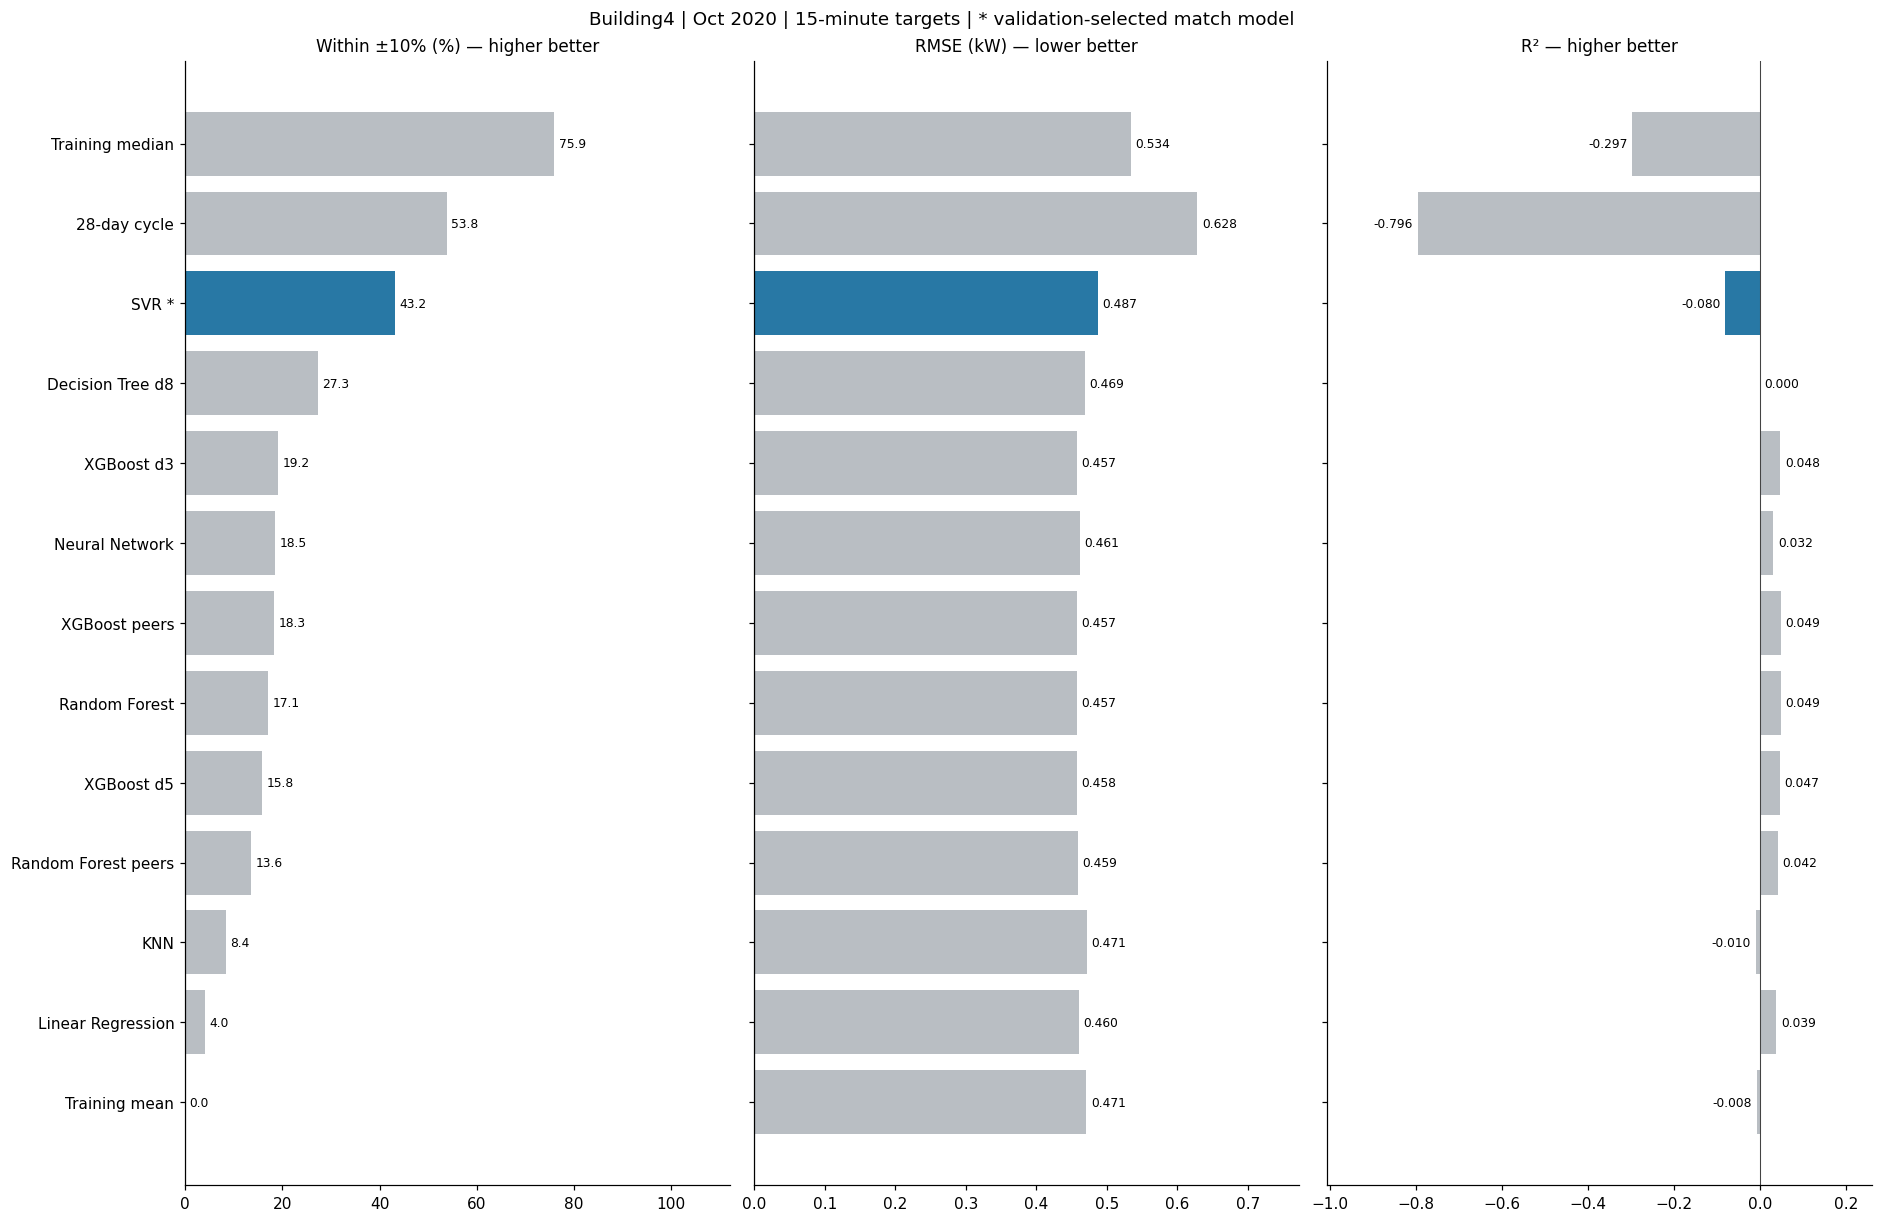

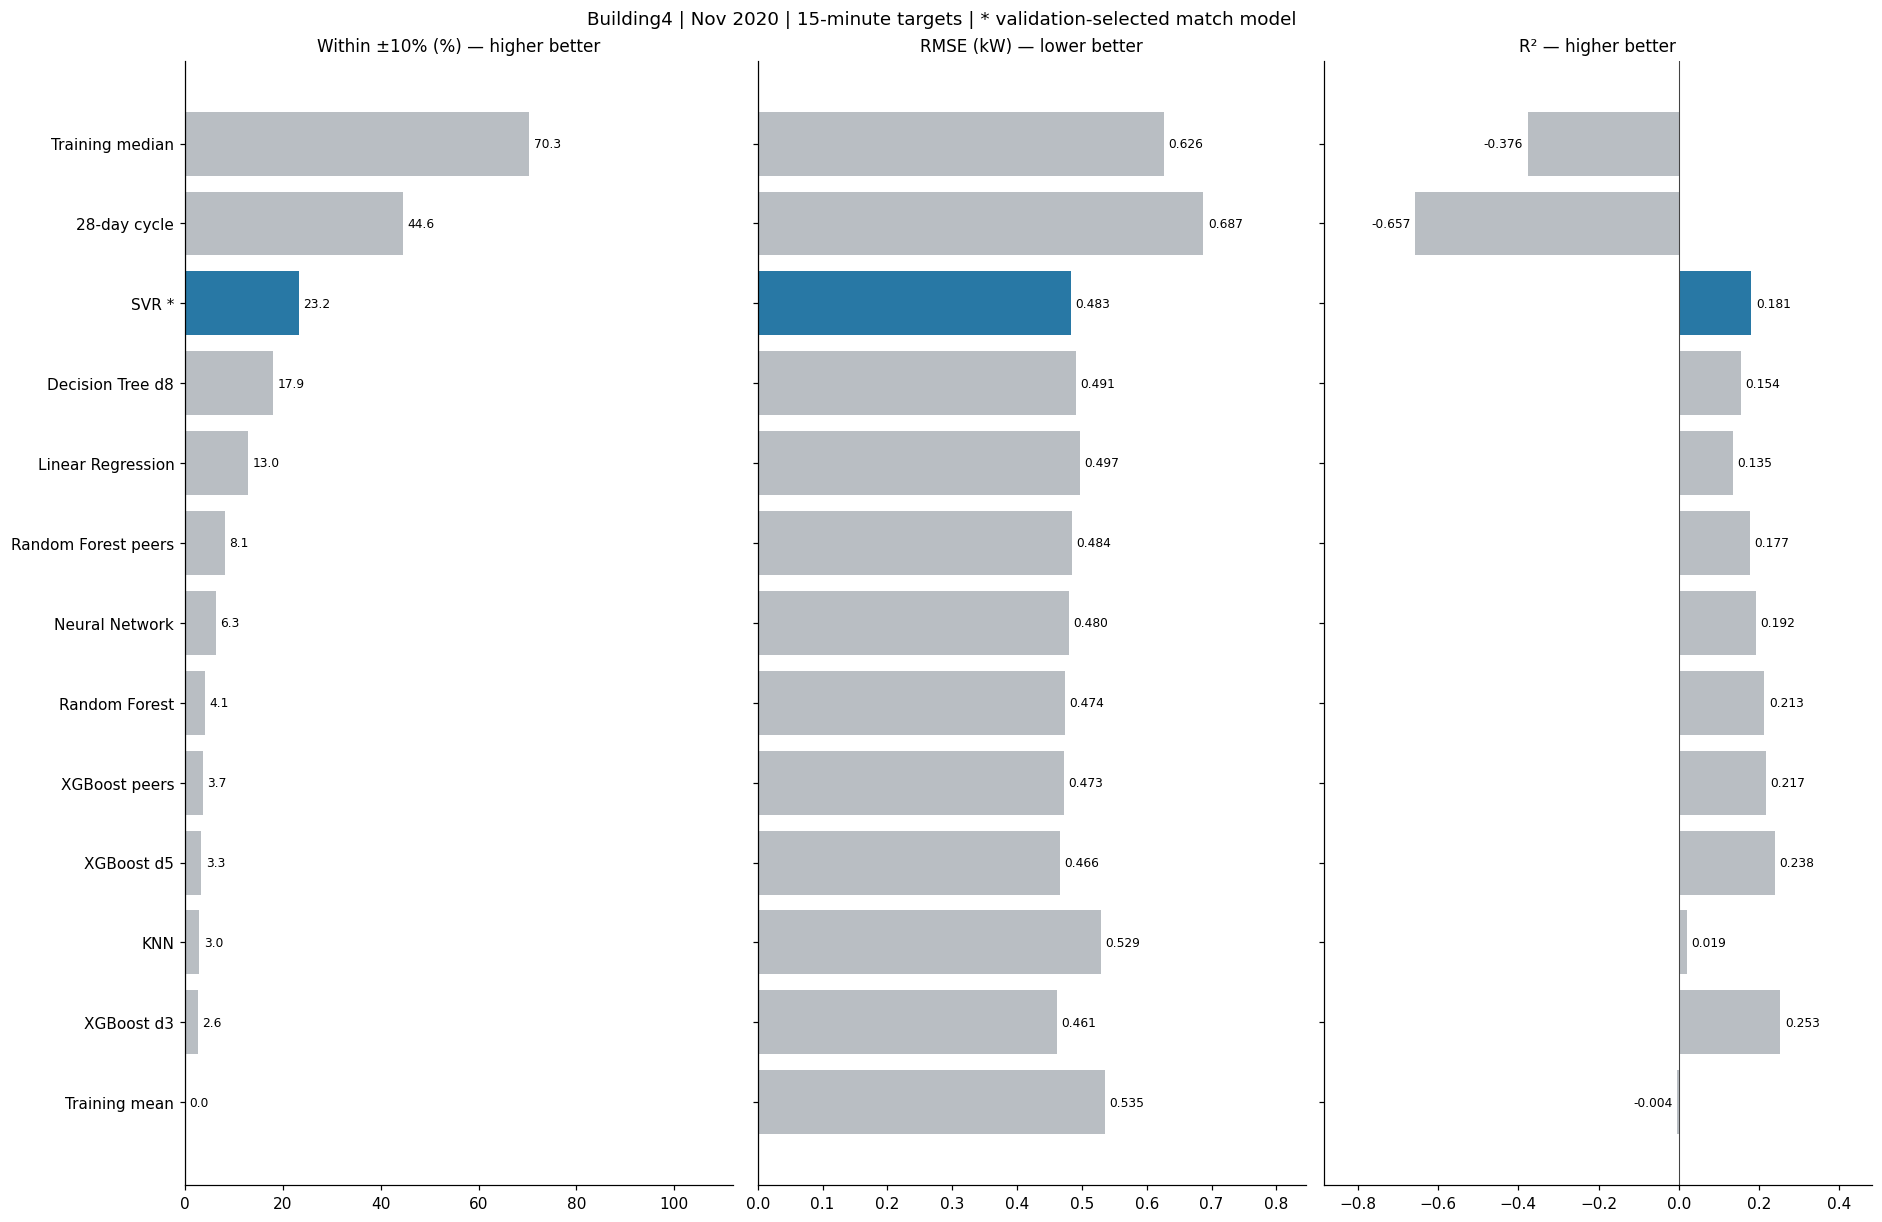

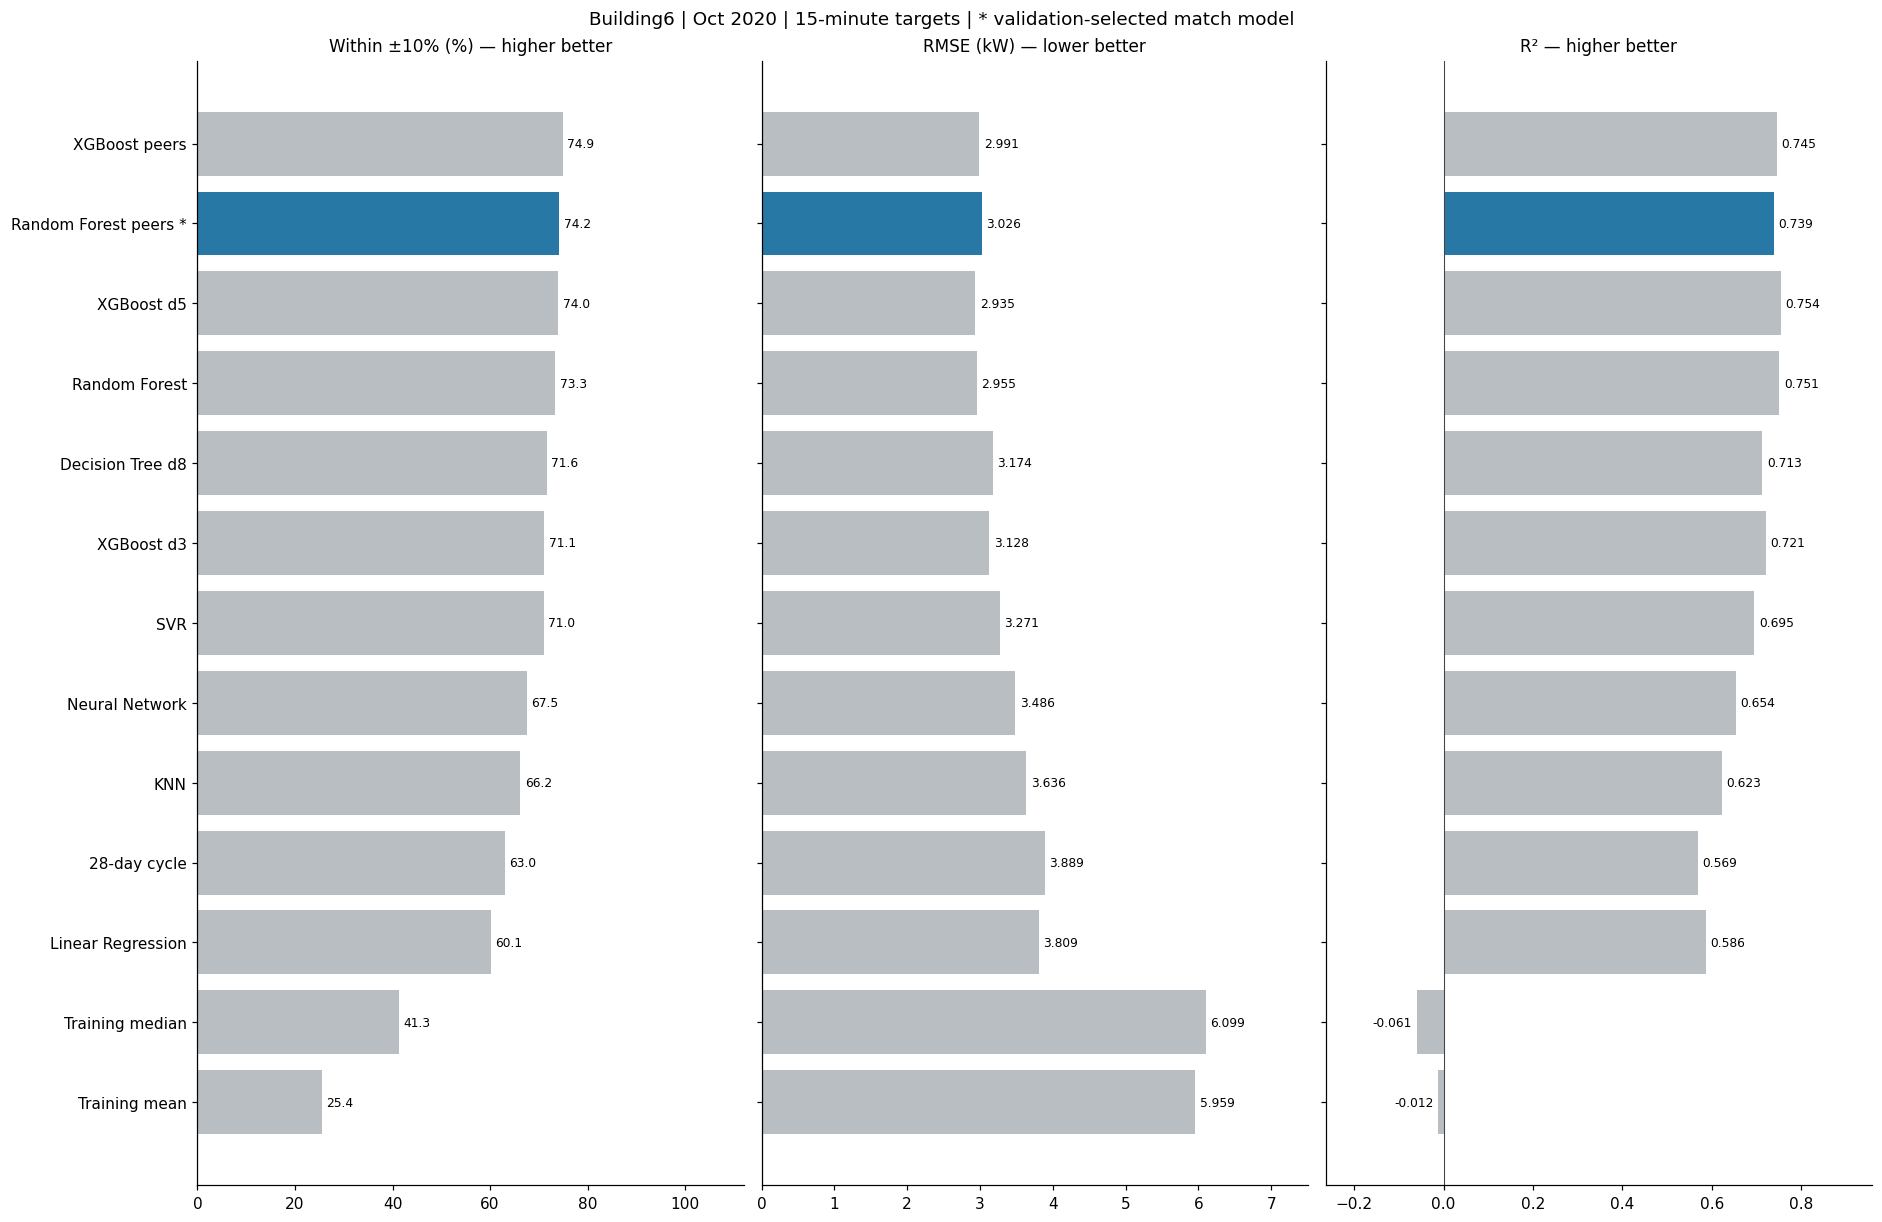

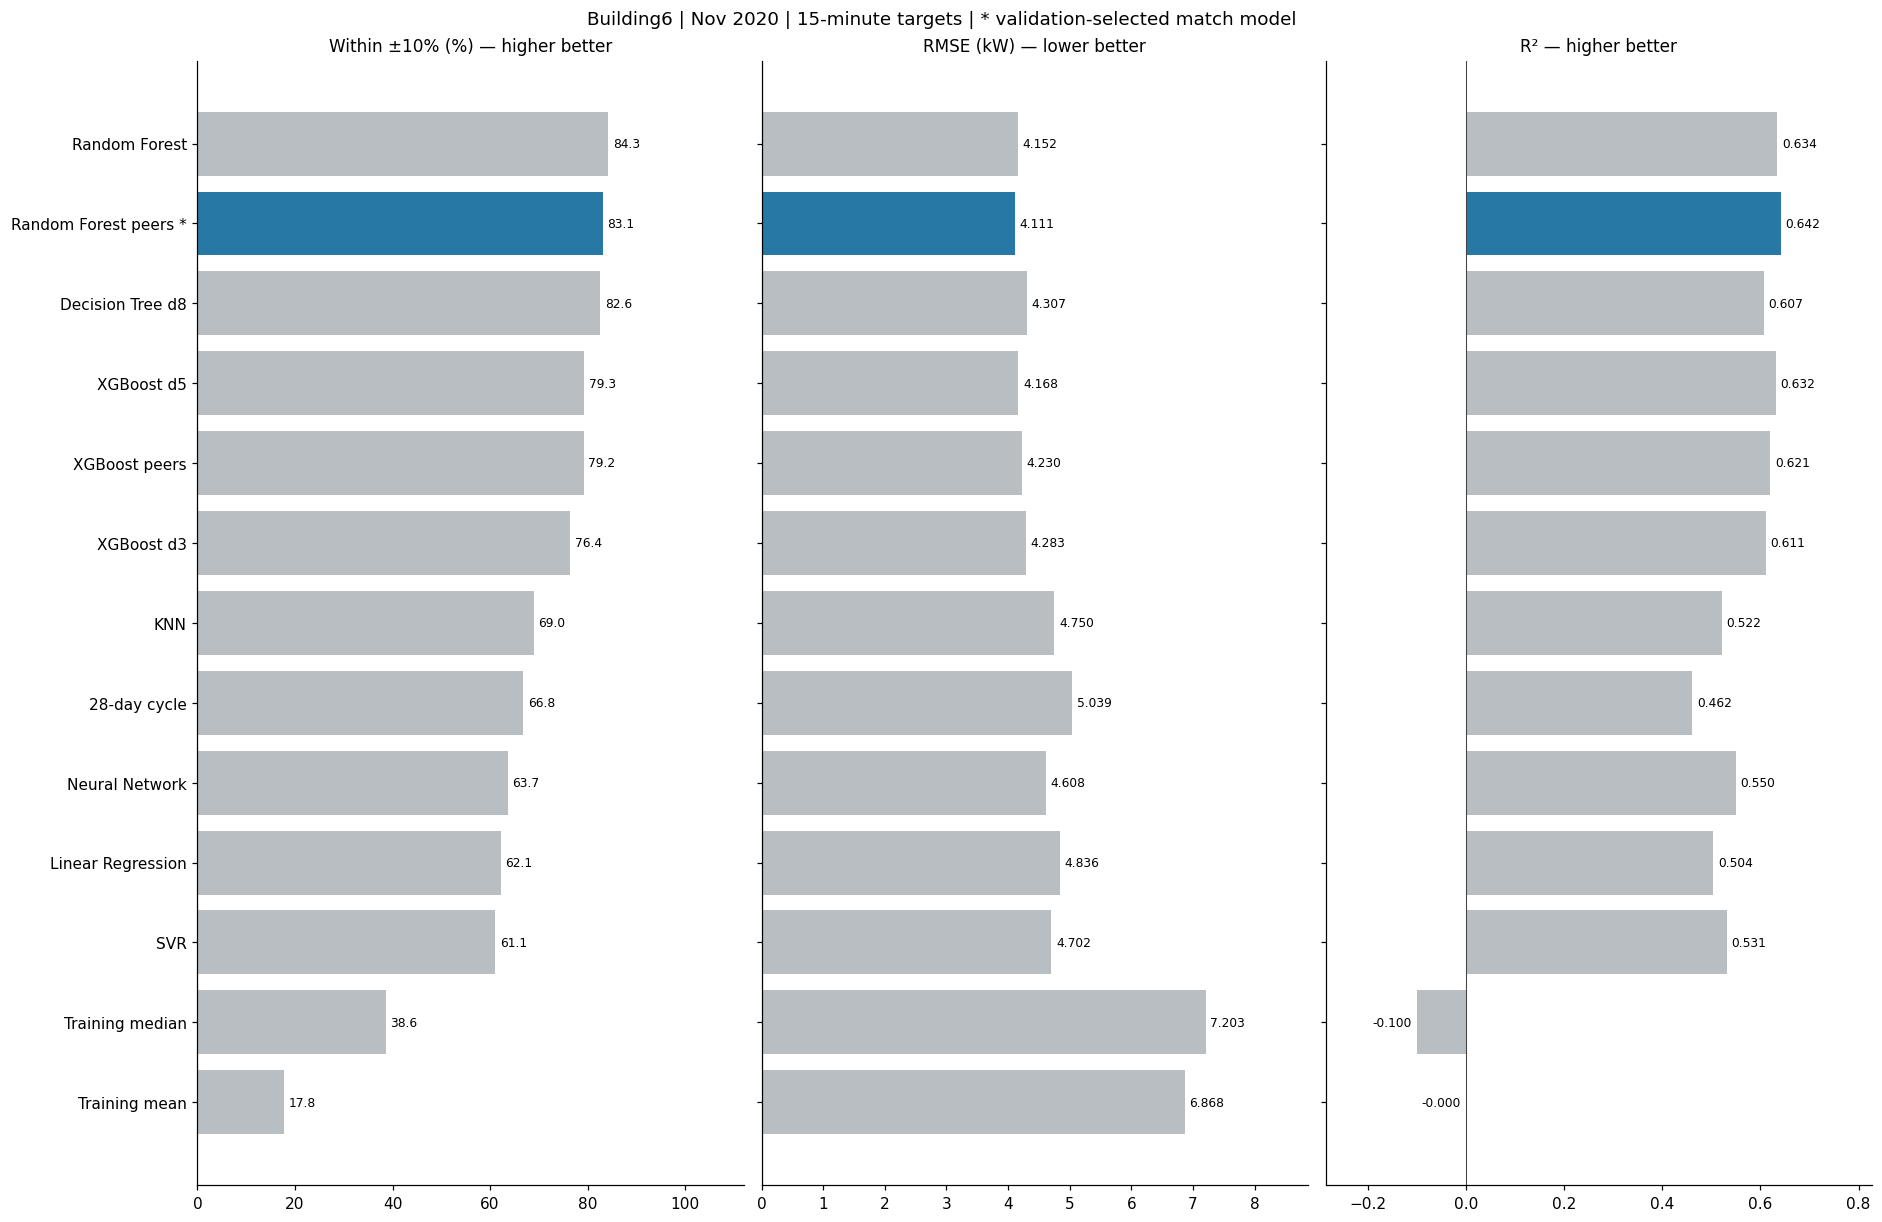

In [19]:

for b in ['Building4','Building6']:
    for month in ['Oct','Nov']:
        z=main[main.Building.eq(b)&main.Month.eq(month)].sort_values('Within10pct',ascending=False)
        winner=selected[(selected.Building==b)&(selected.Month==month)&selected.Selection.eq('Validation match')].Model.iloc[0]
        labels=[name+(' *' if name==winner else '') for name in z.Model]
        colors=['#2878a5' if name==winner else '#b9bec3' for name in z.Model]
        fig,axes=plt.subplots(1,3,figsize=(17,11),layout='constrained')
        for ax,(metric,title) in zip(axes,[('Within10pct','Within ±10% (%) — higher better'),('RMSE','RMSE (kW) — lower better'),('R2','R² — higher better')]):
            bars=ax.barh(np.arange(len(z)),z[metric],color=colors)
            ax.set_yticks(np.arange(len(z)),labels if ax==axes[0] else [])
            ax.invert_yaxis();ax.set_title(title,fontsize=11);ax.axvline(0,color='#444',lw=.7)
            ax.bar_label(bars,fmt='%.1f' if metric=='Within10pct' else '%.3f',padding=3,fontsize=8)
            if metric=='Within10pct':ax.set_xlim(0,112)
            elif metric=='RMSE':ax.set_xlim(0,z.RMSE.max()*1.23)
            else:ax.margins(x=.25)
        fig.suptitle(f'{b} | {month} 2020 | 15-minute targets | * validation-selected match model')
        fig.savefig(OUT/f'{b}_{month}_model_comparison.png',dpi=140,bbox_inches='tight');plt.show()


## 8. Best-match forecast versus actual
Show the full 15-minute month and the first seven days, without daily averaging. Missing actual readings remain gaps. The RMSE-selected forecast is also shown to reveal the trade-off. Retrospective maximum plots are labelled separately.

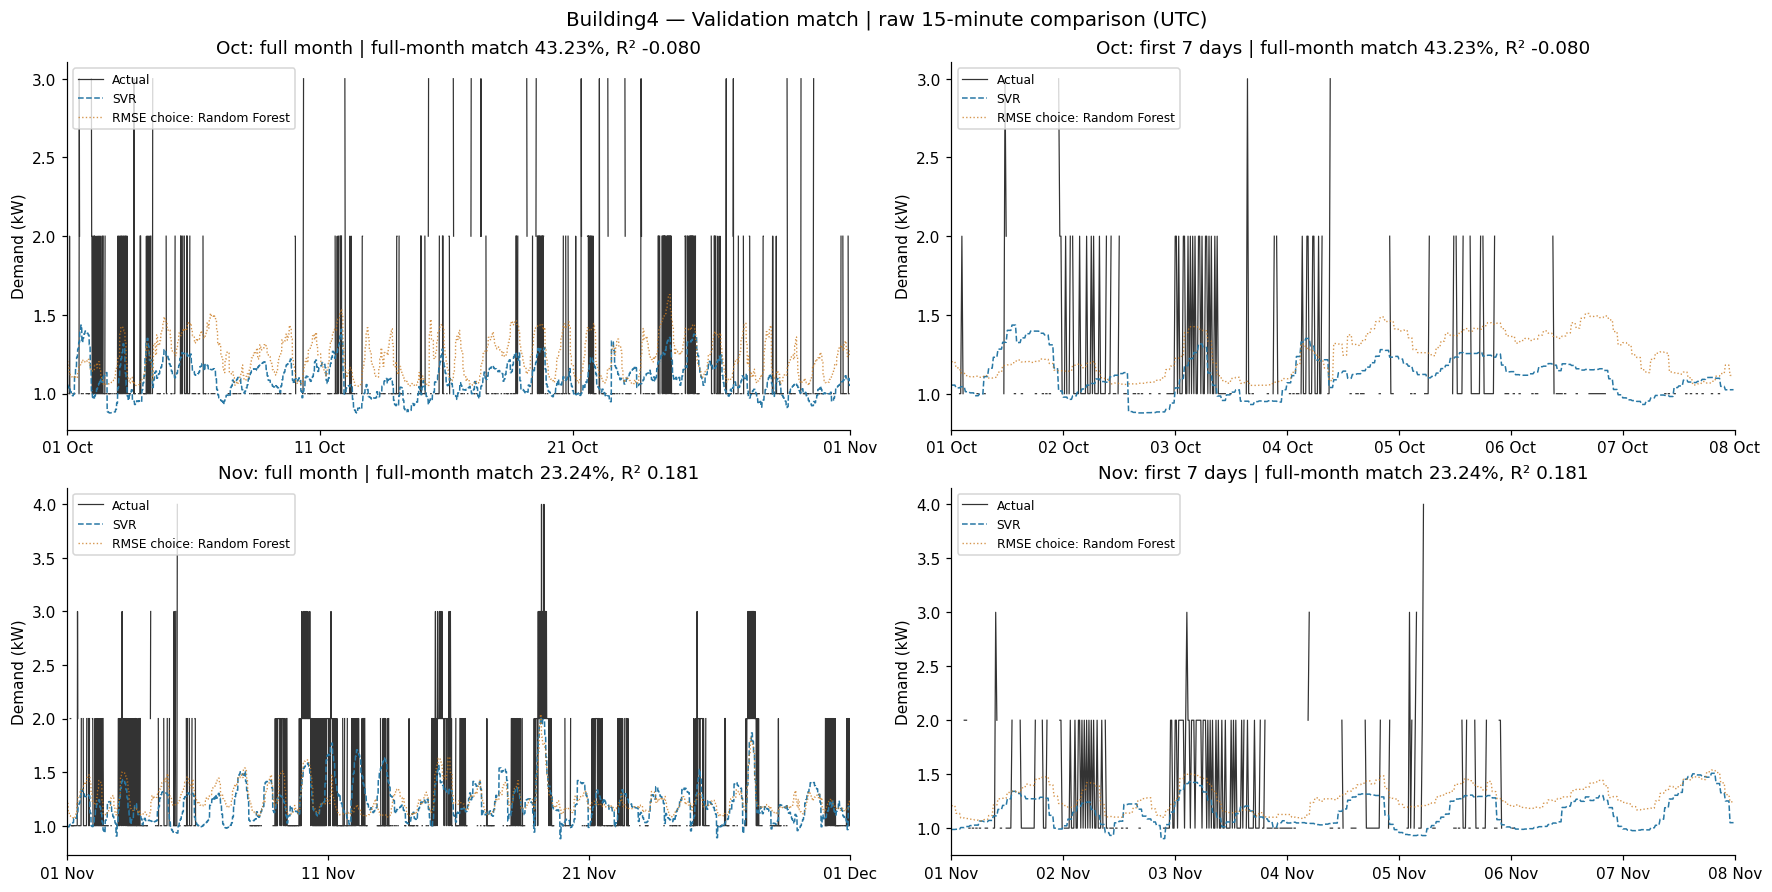

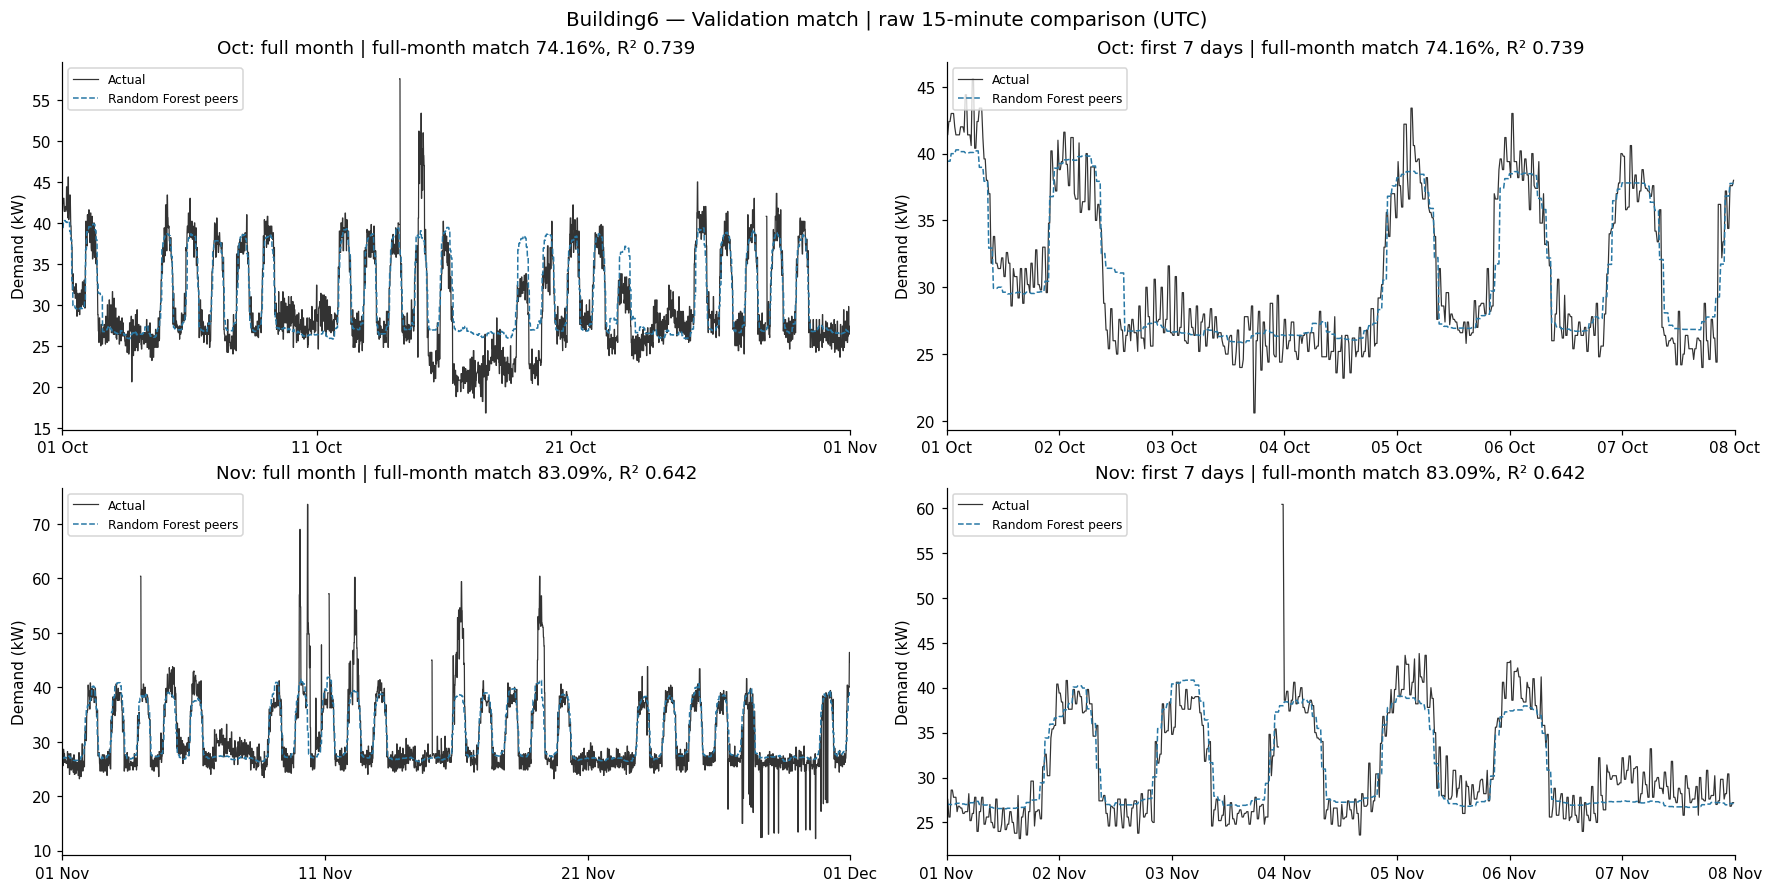

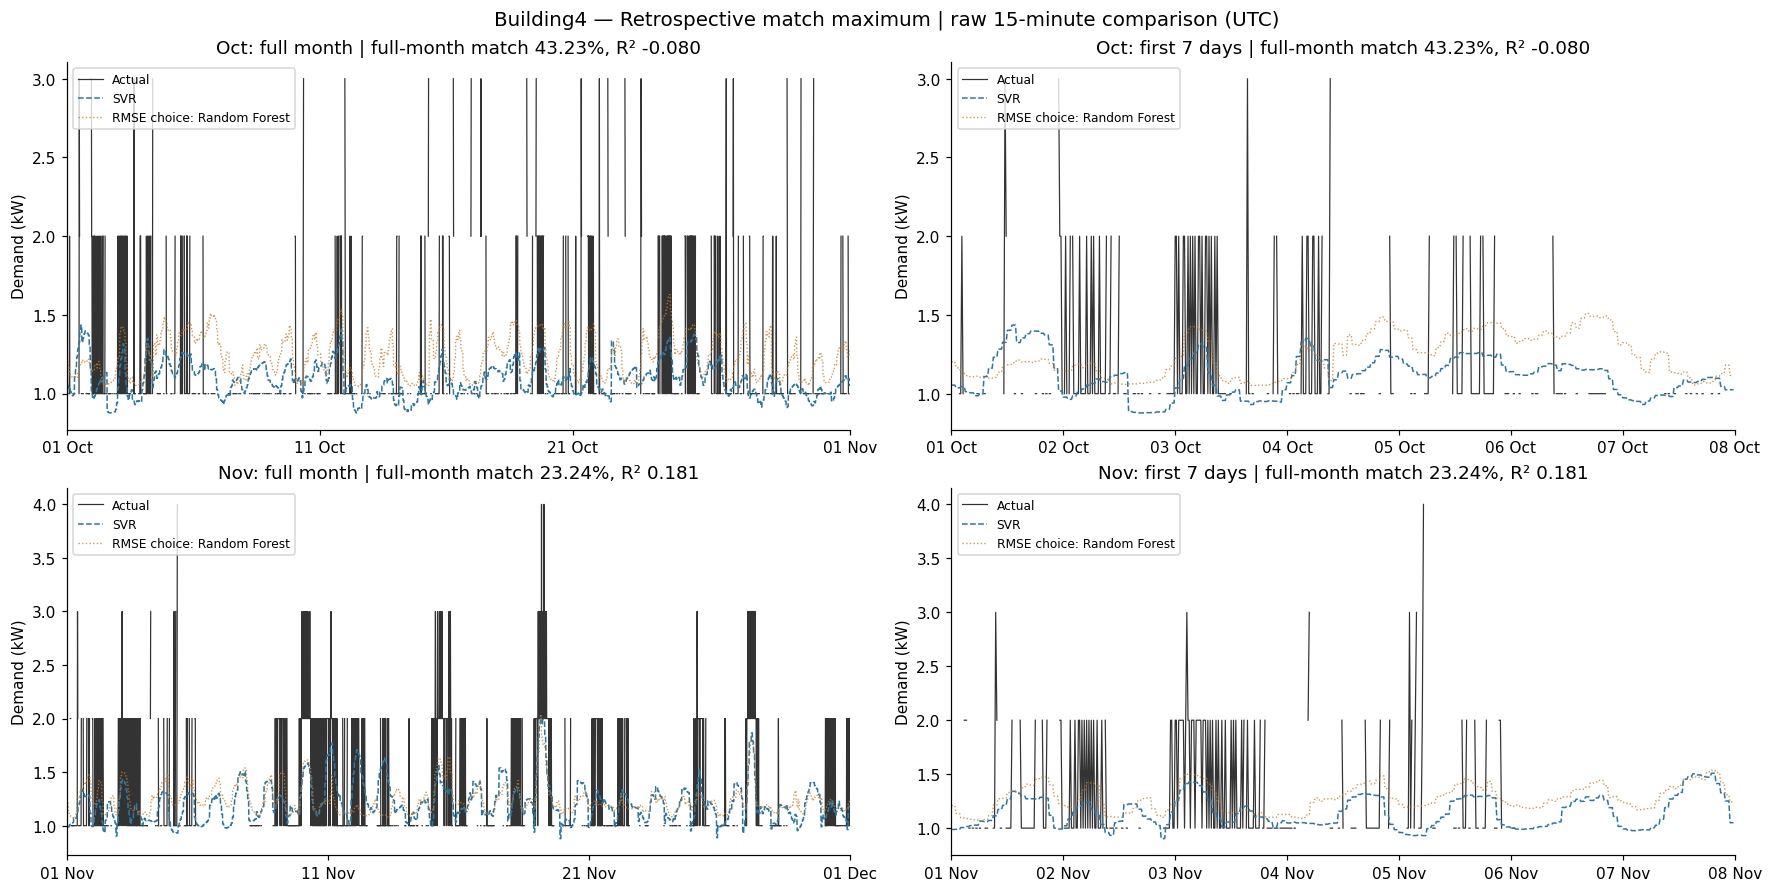

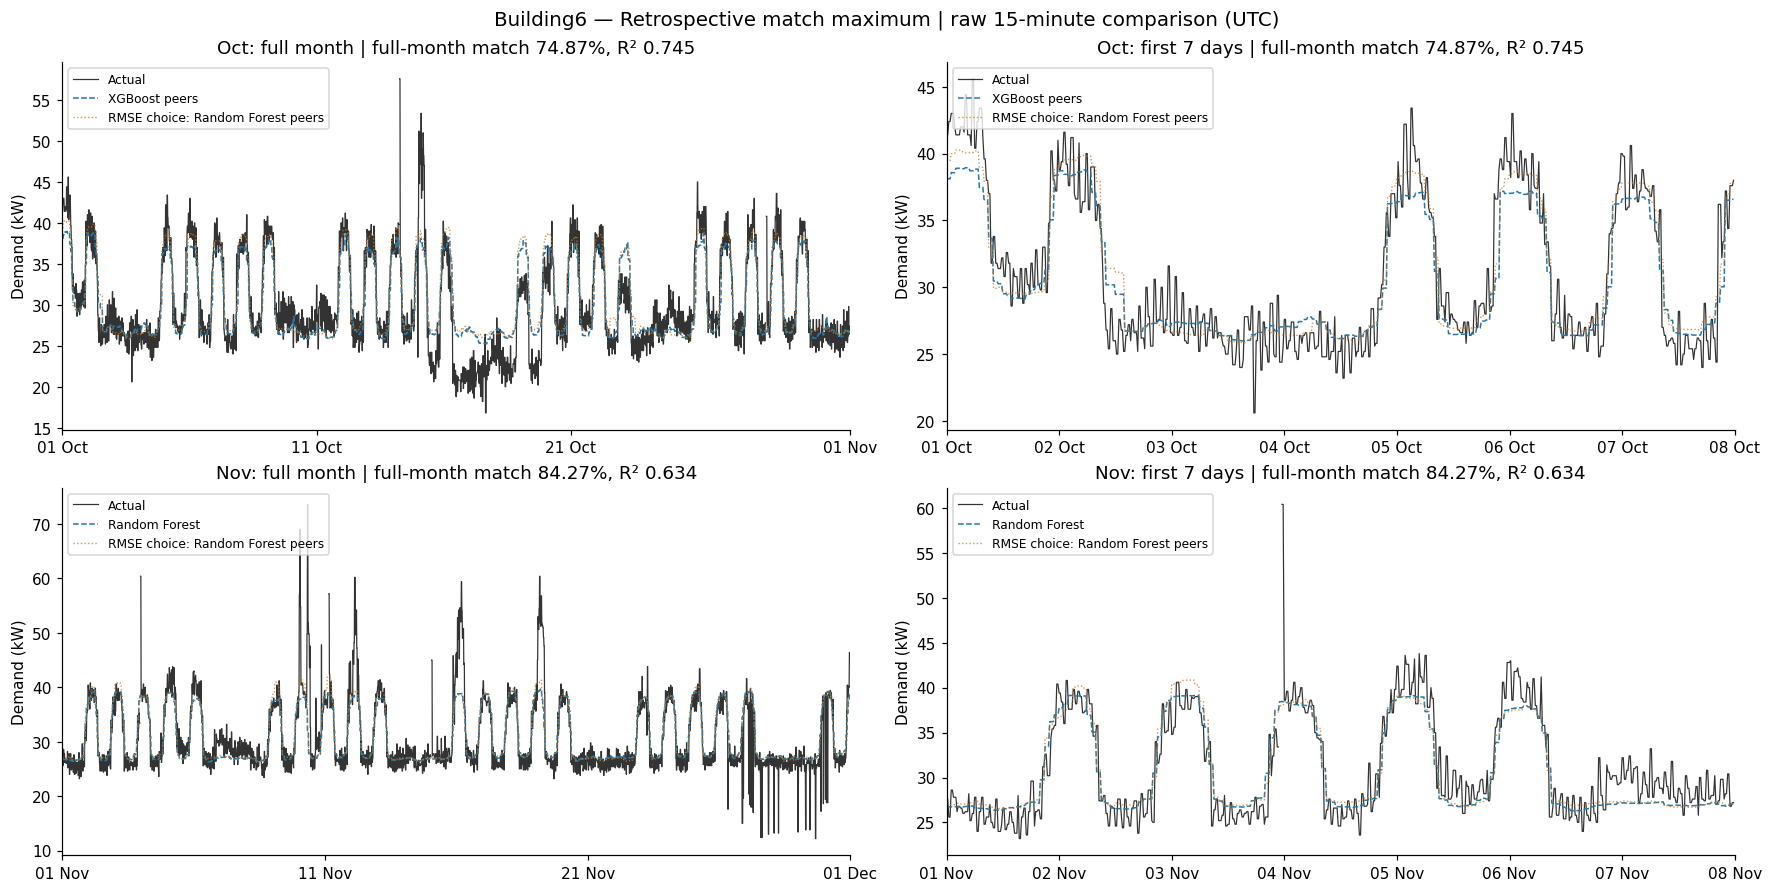

In [20]:

import matplotlib.dates as mdates
for objective in ['Validation match','Retrospective match maximum']:
    for b in ['Building4','Building6']:
        fig,axes=plt.subplots(2,2,figsize=(16,8),layout='constrained')
        for row,month in enumerate(['Oct','Nov']):
            chosen=selected[(selected.Building==b)&selected.Month.eq(month)&selected.Selection.eq(objective)].iloc[0]
            rmse_choice=selected[(selected.Building==b)&selected.Month.eq(month)&selected.Selection.eq('Validation RMSE')].iloc[0]
            z=predictions[predictions.Building.eq(b)&predictions.Month.eq(month)&predictions.Model.eq(chosen.Model)].set_index('timestamp_UTC')
            other=predictions[predictions.Building.eq(b)&predictions.Month.eq(month)&predictions.Model.eq(rmse_choice.Model)].set_index('timestamp_UTC')
            lo,hi=folds[month]
            for col in [0,1]:
                ax=axes[row,col];stop=hi if col==0 else lo+pd.Timedelta(days=7)
                q=z.loc[(z.index>=lo)&(z.index<stop)]
                ax.plot(q.index,q.actual_kW,color='#333333',lw=.8,label='Actual')
                ax.plot(q.index,q.predicted_kW,color='#2878a5',lw=1,ls='--',label=chosen.Model)
                if rmse_choice.Model!=chosen.Model:
                    ax.plot(q.index,other.predicted_kW.reindex(q.index),color='#cb7b20',alpha=.8,lw=.9,ls=':',label='RMSE choice: '+rmse_choice.Model)
                if col==0: ax.set_xticks([lo,lo+pd.Timedelta(days=10),lo+pd.Timedelta(days=20),hi])
                ax.set_xlim(lo,stop);ax.set_ylabel('Demand (kW)');ax.legend(fontsize=8,loc='upper left')
                ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
                ax.set_title(f'{month}: '+('full month' if col==0 else 'first 7 days')+f' | full-month match {chosen.Within10pct:.2f}%, R² {chosen.R2:.3f}')
        fig.suptitle(f'{b} — {objective} | raw 15-minute comparison (UTC)',fontsize=13)
        fig.savefig(OUT/f'{b}_{objective.replace(" ","_")}_actual_vs_predicted.png',dpi=140,bbox_inches='tight');plt.show()


## 9. October versus November results and saved deliverables
November uses October actuals for training. A change in score also reflects a different evaluation month and coverage, so it cannot alone measure the benefit of adding October data.

Verified fresh fits: 120 | score rows: 312 | forecast rows: 456768
Saved scores, predictions, fitted October/November models and PNG charts to: C:\Users\50851\Documents\Codex\2026-08-14\kan\outputs\building46_requested_models


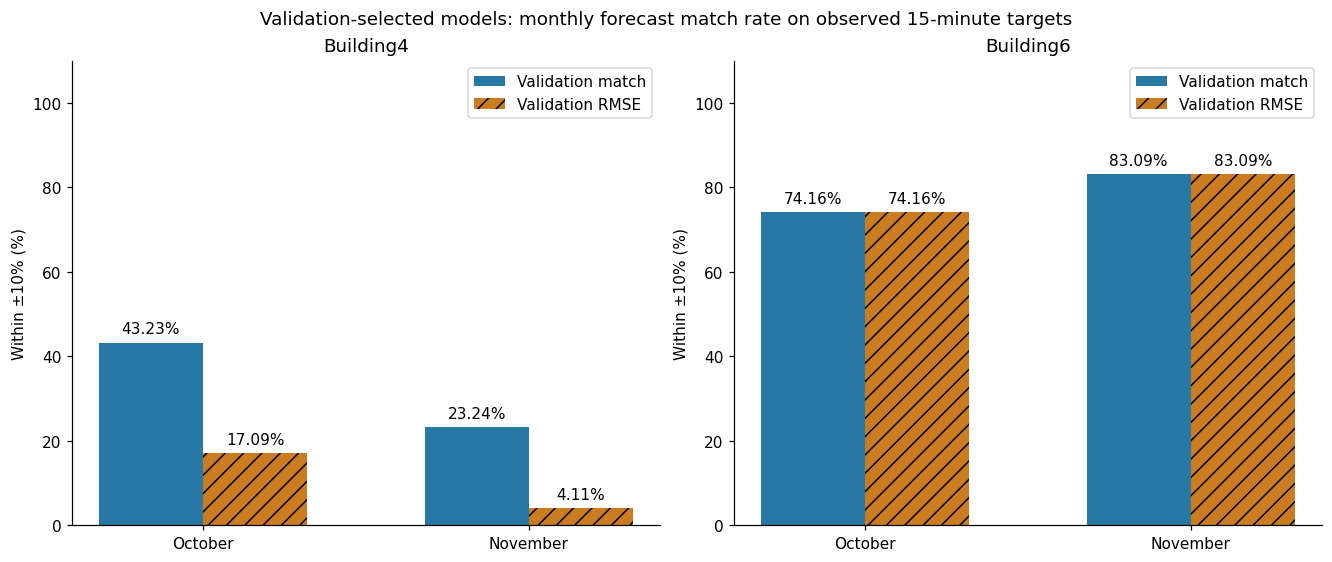

,Building,Month,Selection,Model,Within10pct,RMSE,R2,MASE
0,Building4,Oct,Validation match,SVR,43.2289,0.4872,-0.0801,0.6673
1,Building4,Oct,Validation RMSE,Random Forest,17.0905,0.4571,0.0491,0.7775
3,Building4,Nov,Validation match,SVR,23.2432,0.4833,0.1810,0.7729
4,Building4,Nov,Validation RMSE,Random Forest,4.1081,0.4736,0.2134,0.8019
6,Building6,Oct,Validation match,Random Forest peers,74.1588,3.0257,0.7390,0.7497
7,Building6,Oct,Validation RMSE,Random Forest peers,74.1588,3.0257,0.7390,0.7497
9,Building6,Nov,Validation match,Random Forest peers,83.0898,4.1108,0.6416,0.7719
10,Building6,Nov,Validation RMSE,Random Forest peers,83.0898,4.1108,0.6416,0.7719


In [21]:

primary=selected[selected.Selection.isin(['Validation match','Validation RMSE'])]
fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
for ax,b in zip(axes,['Building4','Building6']):
    for k,(criterion,color) in enumerate([('Validation match','#2878a5'),('Validation RMSE','#cb7b20')]):
        z=primary[primary.Building.eq(b)&primary.Selection.eq(criterion)].set_index('Month').loc[['Oct','Nov']]
        bars=ax.bar(np.arange(2)+(k-.5)*.32,z.Within10pct,width=.32,label=criterion,color=color,hatch='' if k==0 else '//')
        ax.bar_label(bars,fmt='%.2f%%',padding=4)
    ax.set_xticks([0,1],['October','November']);ax.set_ylim(0,110);ax.set_ylabel('Within ±10% (%)');ax.set_title(b);ax.legend()
fig.suptitle('Validation-selected models: monthly forecast match rate on observed 15-minute targets')
fig.savefig(OUT/'selected_match_summary.png',dpi=150);plt.show()
display(primary[['Building','Month','Selection','Model','Within10pct','RMSE','R2','MASE']].round(4))
assert len(training_log)==len(specs)*2*len(folds)
assert not predictions[['Building','Month','Model','timestamp_UTC']].duplicated().any()
for r in selected.itertuples():
    q=predictions[(predictions.Building==r.Building)&(predictions.Month==r.Month)&(predictions.Model==r.Model)]
    a=q.actual_kW.to_numpy();p=q.predicted_kW.to_numpy();mask=np.isfinite(a)
    assert np.isclose(np.sqrt(np.mean((a[mask]-p[mask])**2)),r.RMSE)
    mask &= np.abs(a)>1e-12
    assert np.isclose(100*np.mean(np.abs(a[mask]-p[mask])<=.1*np.abs(a[mask])),r.Within10pct)
print('Verified fresh fits:',len(training_log),'| score rows:',len(scores),'| forecast rows:',len(predictions))
print('Saved scores, predictions, fitted October/November models and PNG charts to:',OUT)


## Takeaways
Read the validation-selected results above alongside the full-resolution plots. Higher tolerance match does not guarantee better peak forecasts. The retrospective maximum is shown only as an observed upper ranking among these candidates. No finite search establishes the highest possible score; future unseen months and operational weather forecasts remain necessary for deployment assessment.